In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [35]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = np.linspace(1,5,51)

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant slope 1/2 L1
MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_li_1d = np.empty((OMEGA.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(OMEGA.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_L1_omega_from_{}_to_{}_num_{}.npy".format(OMEGA[0],OMEGA[-1],OMEGA.shape[0]), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


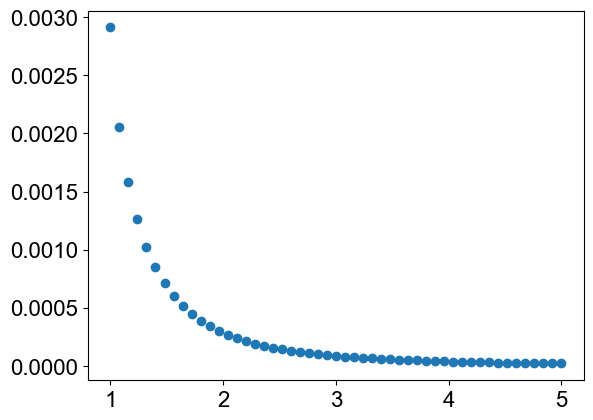

In [36]:
plt.scatter(OMEGA, Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])

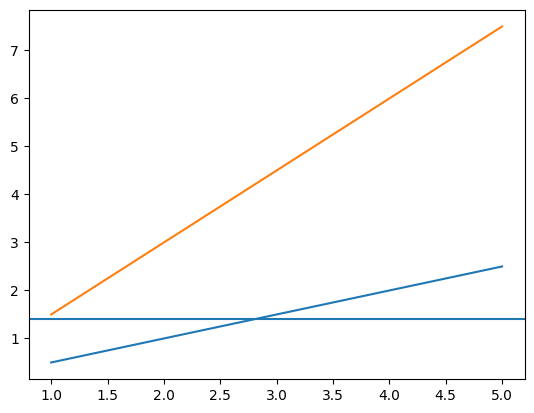

In [12]:
plt.plot(OMEGA, OMEGA/2)
plt.plot(OMEGA, 3*OMEGA/2)
plt.axhline(y=1.4)

In [37]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = np.linspace(1,5,51)

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant mu  in mu vs omega landscape it is horizontal, H1
MU_SC =  1.4   #in between two subbands
MU_SM =  1.4   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_li_1d = np.empty((OMEGA.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(OMEGA.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_H1_omega_from_{}_to_{}_num_{}.npy".format(OMEGA[0],OMEGA[-1],OMEGA.shape[0]), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


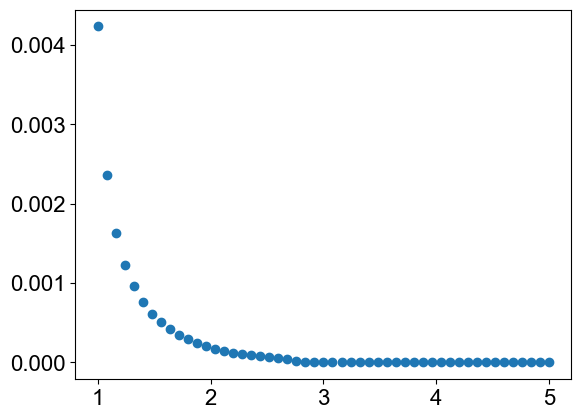

In [38]:
plt.scatter(OMEGA, Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])

In [39]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = 2.5

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant OMEGA in mu vs omega landscape it is vertical, V1
MU_SC =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands
MU_SM =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_li_1d = np.empty((MU_SM.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(MU_SM.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_V1_mu_from_{}_to_{}_num_{}.npy".format(MU_SM[0],MU_SM[-1],MU_SM.shape[0]), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


Text(2, 0.00025, 'first subband = 3.75')

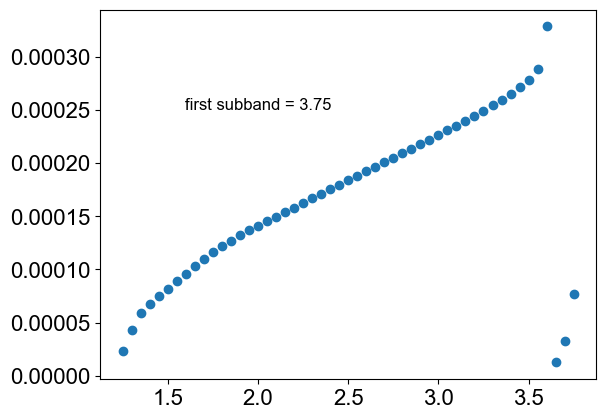

In [40]:
plt.scatter(MU_SM, Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])
plt.text(2, 0.00025, 'first subband = {}'.format(3*OMEGA/2), fontsize=12, ha='center')  # Text at (0, 0)

In [41]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = 1

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant OMEGA in mu vs omega landscape it is vertical, V1
MU_SC =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands
MU_SM =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_li_1d = np.empty((MU_SM.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(MU_SM.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_V1_mu_from_{}_to_{}_omega_{}_num_{}.npy".format(MU_SM[0],MU_SM[-1],OMEGA, MU_SM.shape[0]), Ep_li_1d)


0
5
10
15
20
25
30
35
40
45
50


Text(0.7, 0.004, 'first subband = 1.5')

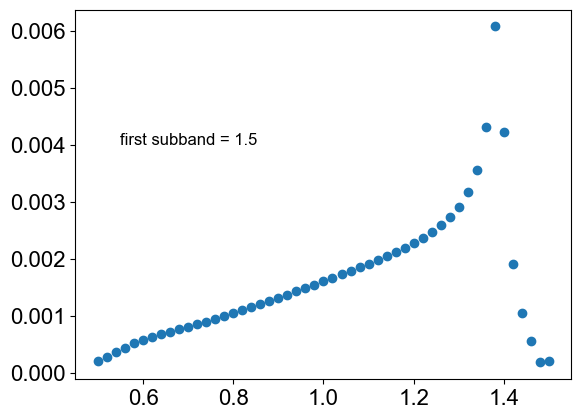

In [42]:
plt.scatter(MU_SM, Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])
plt.text(0.7, 0.004, 'first subband = {}'.format(3*OMEGA/2), fontsize=12, ha='center')  # Text at (0, 0)

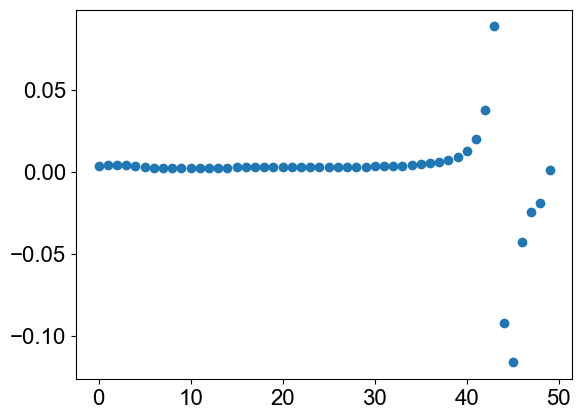

In [43]:
Es = Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2]
S = np.empty(MU_SM.shape[0]-1)

for i in range(MU_SM.shape[0]-1):

    A = Es[i+1] - Es[i]
    B = MU_SM[i+1] - MU_SM[i]
    S[i] = A/B

plt.scatter(np.arange(S.shape[0]),S)

In [45]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = np.linspace(1,5,51)

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant slope 1/2 L1
MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_cu_1d = np.empty((OMEGA.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(OMEGA.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_L1_omega_from_{}_to_{}_soc_{}_num_{}.npy".format(OMEGA[0],OMEGA[-1],ALPHAT, OMEGA.shape[0]), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


(0.0, 0.0004)

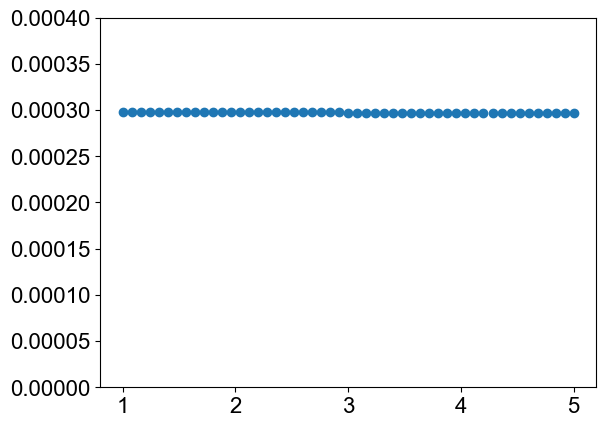

In [46]:
plt.scatter(OMEGA, Ep_cu_1d[:,K//2+1]-Ep_cu_1d[:,K//2])
plt.ylim(ymin=0, ymax = 0.0004)

In [47]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = np.linspace(1,5,51)

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant mu  in mu vs omega landscape it is horizontal, H1
MU_SC =  1.4   #in between two subbands
MU_SM =  1.4   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_cu_1d = np.empty((OMEGA.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(OMEGA.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_H1_omega_from_{}_to_{}_soc_{}_num_{}.npy".format(OMEGA[0],OMEGA[-1],ALPHAT, OMEGA.shape[0]), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


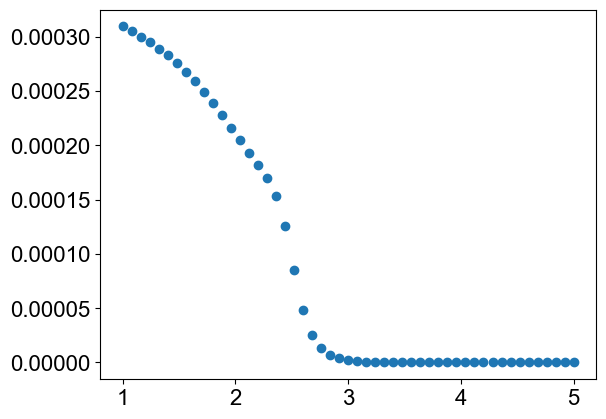

In [48]:
plt.scatter(OMEGA, Ep_cu_1d[:,K//2+1]-Ep_cu_1d[:,K//2])

In [49]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = 2.5

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant OMEGA in mu vs omega landscape it is vertical, V1
MU_SC =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands
MU_SM =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_cu_1d = np.empty((MU_SM.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(MU_SM.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_V1_mu_from_{}_to_{}_num_{}.npy".format(MU_SM[0],MU_SM[-1],MU_SM.shape[0]), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


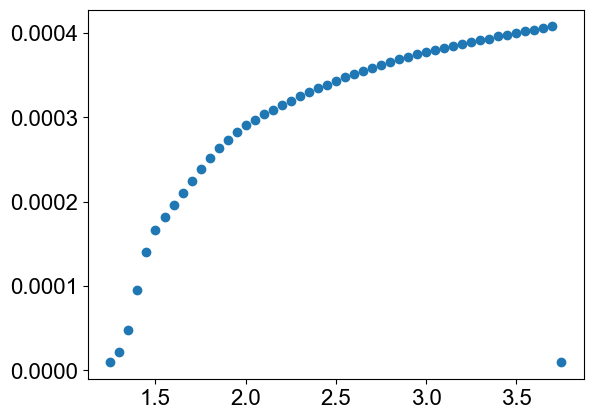

In [51]:
Ep_cu_1d = np.load("cubic_E_V1_mu_from_1.25_to_3.75_num_51.npy")
plt.scatter(MU_SM, Ep_cu_1d[:,K//2+1]-Ep_cu_1d[:,K//2])
#plt.text(2, 0.00025, 'first subband = {}'.format(3*OMEGA/2), fontsize=12, ha='center')  # Text at (0, 0)

In [52]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400 

#LY = 75           # Width in nm
#OMEGA = 2*4*hbm/LY**2/MEFF_SC


OMEGA = 1

#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)


### MU is a line with constant OMEGA in mu vs omega landscape it is vertical, V1
MU_SC =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands
MU_SM =  np.linspace(OMEGA/2, 3*OMEGA/2, 51)   #in between two subbands

#print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

#print("MU =", MU_SC)

K = 8

Ep_cu_1d = np.empty((MU_SM.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(MU_SM.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_V1_mu_from_{}_to_{}_num_{}.npy".format(MU_SM[0],MU_SM[-1],MU_SM.shape[0]), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


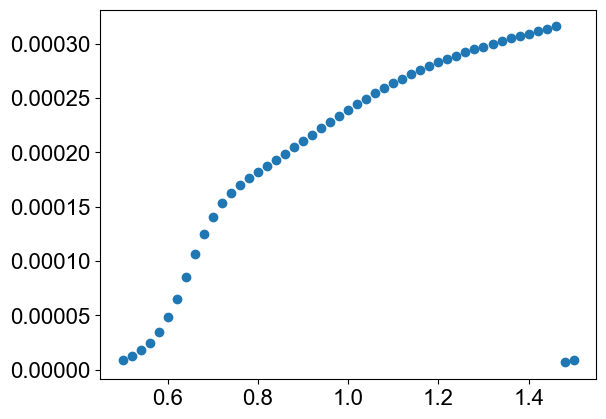

In [53]:
plt.scatter(MU_SM, Ep_cu_1d[:,K//2+1]-Ep_cu_1d[:,K//2])
#plt.text(2, 0.00025, 'first subband = {}'.format(3*OMEGA/2), fontsize=12, ha='center')  # Text at (0, 0)

In [9]:
Eli_L1 = np.load("linear_E_L1_omega_from_1.0_to_5.0_num_51.npy")
Eli_H1 = np.load("linear_E_H1_omega_from_1.0_to_5.0_num_51.npy")
Eli_V1 = np.load("linear_E_V1_mu_from_0.5_to_1.5_omega_1_num_51.npy")
Eli_V2 = np.load("linear_E_V1_mu_from_1.25_to_3.75_num_51.npy")

Ecu_L1 = np.load("cubic_E_L1_omega_from_1.0_to_5.0_soc_400_num_51.npy")
Ecu_H1 = np.load("cubic_E_H1_omega_from_1.0_to_5.0_soc_400_num_51.npy")
Ecu_V1 = np.load("cubic_E_V1_mu_from_0.5_to_1.5_num_51.npy")
Ecu_V2 = np.load("cubic_E_V1_mu_from_1.25_to_3.75_num_51.npy")
OMEGA = np.linspace(1,5,51)

MU_SM =  np.linspace(1/2, 3/2, 51)   #in between two subbands
MU_SM1 =  np.linspace(2.5/2, 3/2, 51)   #in between two subbands

DELTA = 0.165

K=8

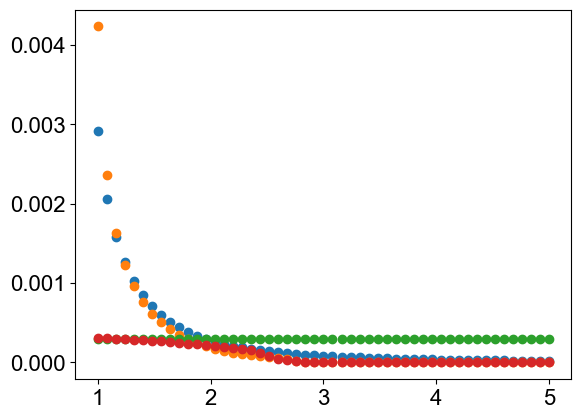

In [10]:
plt.scatter(OMEGA, Eli_L1[:,K//2+1]-Eli_L1[:,K//2])
plt.scatter(OMEGA, Eli_H1[:,K//2+1]-Eli_H1[:,K//2])

plt.scatter(OMEGA, Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2])
plt.scatter(OMEGA, Ecu_H1[:,K//2+1]-Ecu_H1[:,K//2])




Text(0, 0.5, 'Spin splitting, $\\dfrac{E_s}{\\Delta}$')

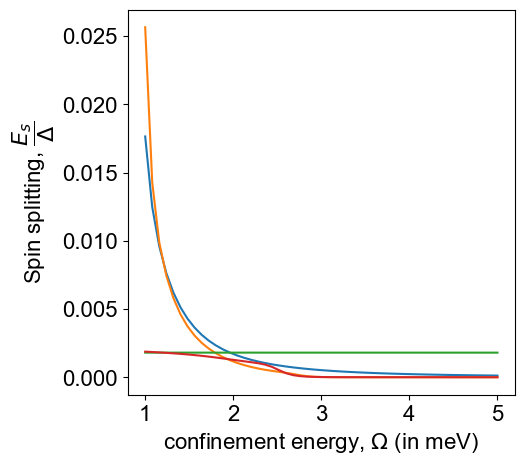

In [11]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))

plt.plot(OMEGA, (Eli_L1[:,K//2+1]-Eli_L1[:,K//2])/DELTA)
plt.plot(OMEGA, (Eli_H1[:,K//2+1]-Eli_H1[:,K//2])/DELTA)

plt.plot(OMEGA, (Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2])/DELTA)
plt.plot(OMEGA, (Ecu_H1[:,K//2+1]-Ecu_H1[:,K//2])/DELTA)


# Add labels
plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
plt.ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$')

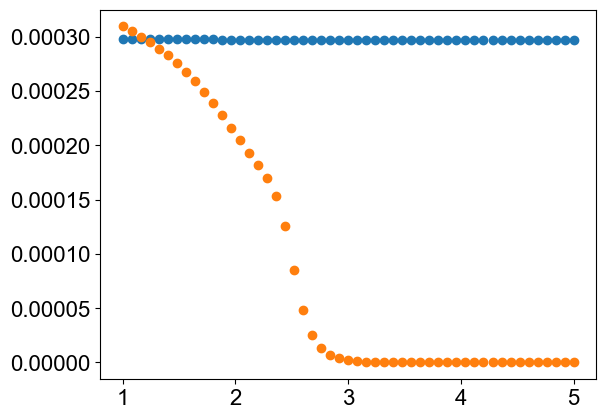

In [63]:
plt.scatter(OMEGA, Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2])
plt.scatter(OMEGA, Ecu_H1[:,K//2+1]-Ecu_H1[:,K//2])


Text(0, 0.5, 'Spin splitting, $\\dfrac{E_s}{\\Delta}$')

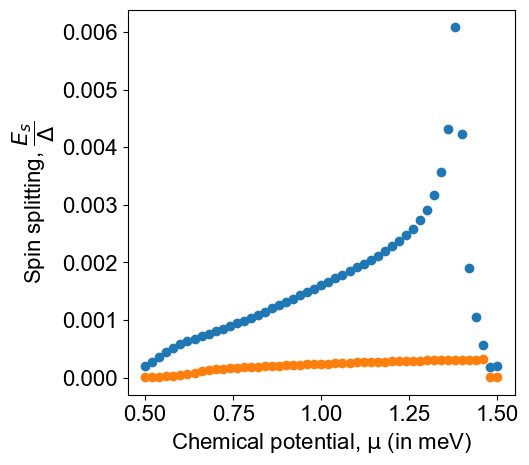

In [13]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))

plt.scatter(MU_SM,  Eli_V1[:,K//2+1]-Eli_V1[:,K//2])
plt.scatter(MU_SM,  Ecu_V1[:,K//2+1]-Ecu_V1[:,K//2])


# Add labels
plt.xlabel(r'Chemical potential, $\mathrm{\mu}$ (in meV)')
plt.ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$')

Text(0, 0.5, 'Spin splitting, $\\dfrac{E_s}{\\Delta}$')

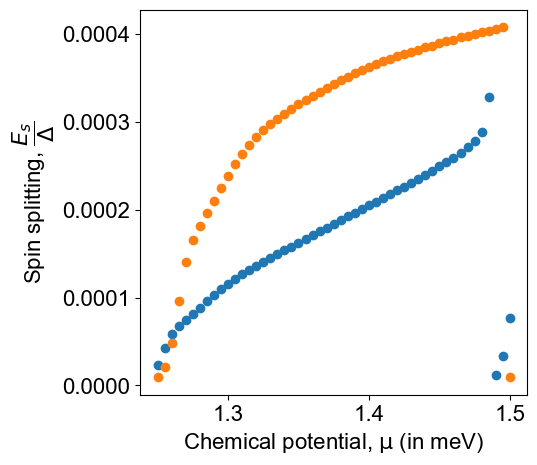

In [14]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))

plt.scatter(MU_SM1,  Eli_V2[:,K//2+1]-Eli_V2[:,K//2])
plt.scatter(MU_SM1,  Ecu_V2[:,K//2+1]-Ecu_V2[:,K//2])


# Add labels
plt.xlabel(r'Chemical potential, $\mathrm{\mu}$ (in meV)')
plt.ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$')

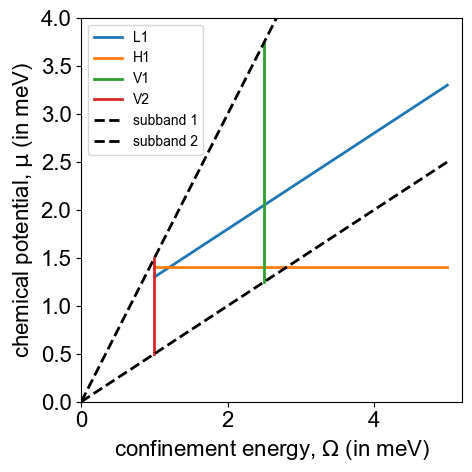

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))

# Data for the plot
OMEGA = np.linspace(1, 5, 21)
MU = np.linspace(1, 5, 21)

# Plot lines with different labels
plt.plot(OMEGA, OMEGA / 2 + 0.8, lw=2, label='L1')
plt.plot(OMEGA, np.ones(21) * 1.4, lw=2, label='H1')
plt.plot(np.ones(21) * 2.5, np.linspace(2.5 / 2, 7.5 / 2, 21), lw=2, label='V1')
plt.plot(np.ones(21) * 1, np.linspace(1 / 2, 3 / 2, 21), lw=2, label='V2')

# Set axis limits
plt.ylim(ymax=4, ymin=0)
plt.xlim(xmin=0)

# Add labels
plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')

# Add dashed lines for subbands
for i in range(2):
    plt.plot(np.linspace(0, 5, 21), (2 * i + 1) * np.linspace(0, 5, 21) / 2, lw=2, linestyle='dashed', color='black', label=f'subband {i+1}')

# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Show plot
plt.tight_layout()
plt.show()
